# Object Detection Basics

## Object Detection Problem Formulation

Object detection is a computer-vision task in which a model identifies
objects present in an image and determines their locations.

Unlike image classification, where the model assigns one or more
class labels to an image, object detection produces a set of
predictions for individual objects.

For each detected object, the output typically contains:

- a class label
- a bounding box
- a confidence score

### Bounding Box

A bounding box defines the image region occupied by a detected object.

A common representation is:

`[x_min, y_min, x_max, y_max]`

where:

- `x_min` = left boundary of the box
- `y_min` = top boundary of the box
- `x_max` = right boundary of the box
- `y_max` = bottom boundary of the box

The coordinates are expressed in the image coordinate system.

### Confidence Score

The confidence score represents the model's confidence in a
particular detection.

A higher confidence score indicates that the model considers the
corresponding detection more likely to be a valid object prediction.

In practical object-detection systems, a confidence threshold can be
used to reject detections with scores below a selected value.

### Classification vs Object Detection

Image classification answers:

`What is present in the image?`

Object detection answers:

`What objects are present, and where are they located?`

For example, an image containing a car and a pedestrian may be
classified as containing both classes. An object detector additionally
produces a separate bounding box and confidence score for each
detected object.

### Autonomous-Driving Relevance

Object detection provides spatial information about surrounding
objects that can later be used by downstream components such as
object tracking, state estimation, planning, and collision avoidance.

The output of the detector therefore forms part of the perception
interface to the broader autonomous-driving pipeline:

`Camera Image → Object Detection → Detected Objects → Tracking / Planning`

In [3]:
# 1-8D
# Object Detection Basics — Environment Check

import sys
import numpy as np
import matplotlib.pyplot as plt

print("Python version:", sys.version)
print("NumPy version:", np.__version__)

Python version: 3.11.9 (tags/v3.11.9:de54cf5, Apr  2 2024, 10:12:12) [MSC v.1938 64 bit (AMD64)]
NumPy version: 2.4.6


In [4]:
#2-8D 
# mage Loading

from PIL import Image
from pathlib import Path

image_path = Path("../../datasets/lane_detection/road_01.jpg")

image = Image.open(image_path)

print("Image size:", image.size)
print("Image mode:", image.mode)

Image size: (3024, 3781)
Image mode: RGB


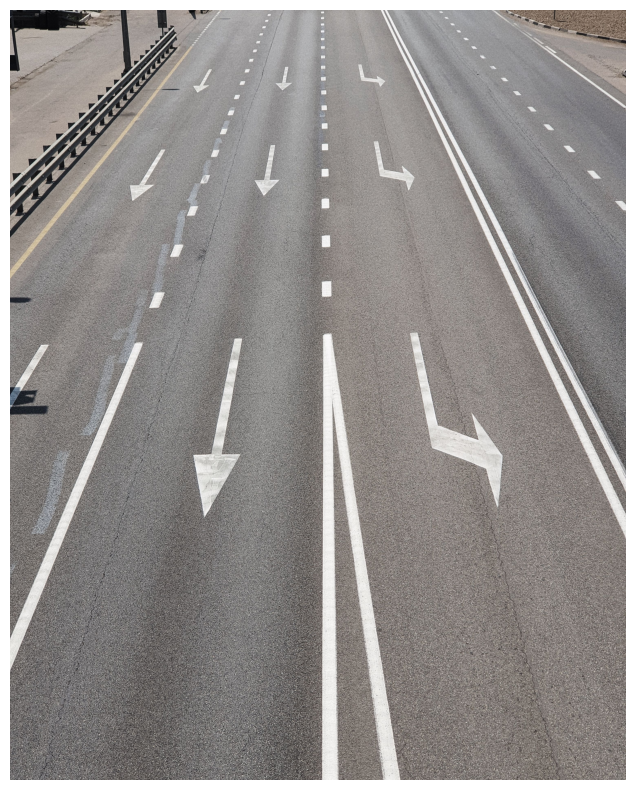

In [5]:
#3-8D 
# Image Display

plt.figure(figsize=(8, 10))
plt.imshow(image)
plt.axis("off")
plt.show()

In [6]:
# 4-8D 
# Bounding box representation

image_width, image_height = image.size

# Example bounding box: [x_min, y_min, x_max, y_max]
bbox = [1200, 1400, 1900, 2600]

print("Image width:", image_width)
print("Image height:", image_height)
print("Bounding box:", bbox)

Image width: 3024
Image height: 3781
Bounding box: [1200, 1400, 1900, 2600]


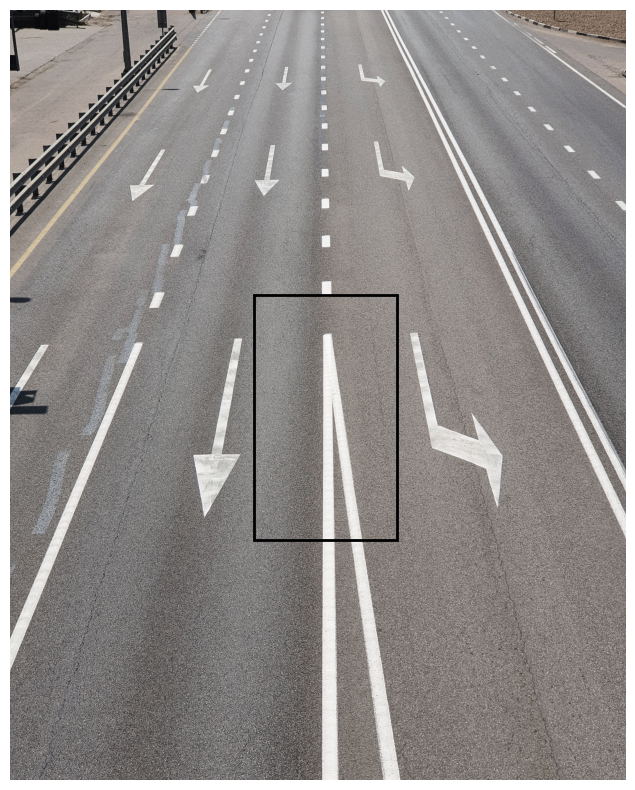

In [7]:
# 5-8D
# Bounding Box Visualization
from matplotlib.patches import Rectangle

x_min, y_min, x_max, y_max = bbox

fig, ax = plt.subplots(figsize=(8, 10))

ax.imshow(image)

box = Rectangle(
    (x_min, y_min),
    x_max - x_min,
    y_max - y_min,
    fill=False,
    linewidth=2
)

ax.add_patch(box)
ax.axis("off")
plt.show()

In [8]:
# 6-8D
# Example Detection Output

class_label = "vehicle"
confidence = 0.87

print("Class:", class_label)
print("Bounding box:", bbox)
print("Confidence:", confidence)

Class: vehicle
Bounding box: [1200, 1400, 1900, 2600]
Confidence: 0.87


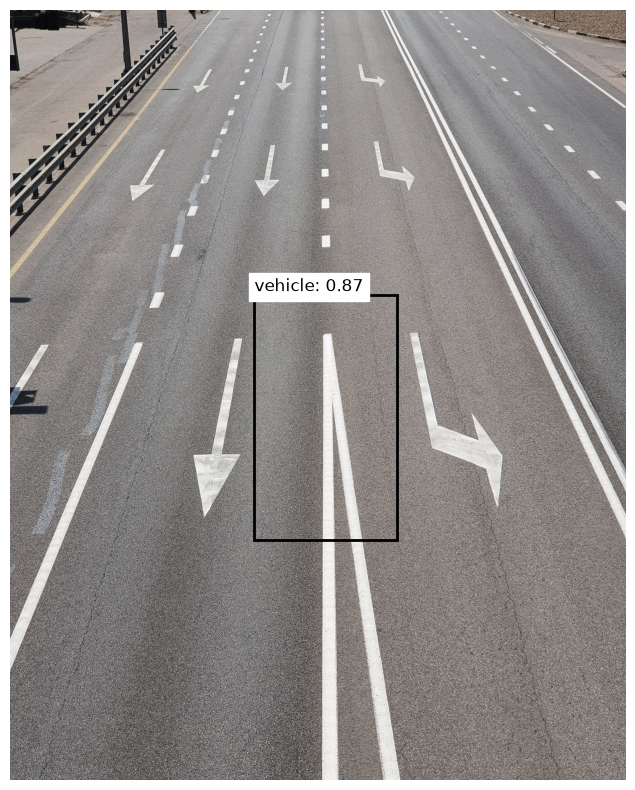

In [9]:
#7-8D 
# Complete Detection Visualization


fig, ax = plt.subplots(figsize=(8, 10))

ax.imshow(image)

box = Rectangle(
    (x_min, y_min),
    x_max - x_min,
    y_max - y_min,
    fill=False,
    linewidth=2
)

ax.add_patch(box)

ax.text(
    x_min,
    y_min - 20,
    f"{class_label}: {confidence:.2f}",
    fontsize=12,
    backgroundcolor="white"
)

ax.axis("off")
plt.show()

In [10]:
# 8-8D
# Confidence thresholding

detections = [
    {"class": "vehicle", "confidence": 0.87},
    {"class": "pedestrian", "confidence": 0.42},
    {"class": "vehicle", "confidence": 0.31},
]

confidence_threshold = 0.50

filtered_detections = [
    detection
    for detection in detections
    if detection["confidence"] >= confidence_threshold
]

print("Confidence threshold:", confidence_threshold)
print("Detections before filtering:", len(detections))
print("Detections after filtering:", len(filtered_detections))

for detection in filtered_detections:
    print(detection)

Confidence threshold: 0.5
Detections before filtering: 3
Detections after filtering: 1
{'class': 'vehicle', 'confidence': 0.87}


In [11]:
# 9-8D
# Deep-Learning Environment Check

import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.12.1+cu132
Torchvision version: 0.27.1+cu132
CUDA available: True


In [12]:
# 10-8D
# GPU Device Check

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA device count:", torch.cuda.device_count())
else:
    print("Using CPU")

GPU: NVIDIA GeForce RTX 3050 Ti Laptop GPU
CUDA device count: 1


In [13]:
# 11-8D — Pretrained Object Detector

from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn,
    FasterRCNN_ResNet50_FPN_Weights
)

weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT

model = fasterrcnn_resnet50_fpn(weights=weights)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

print("Model:", model.__class__.__name__)
print("Device:", device)

Model: FasterRCNN
Device: cuda


In [14]:
# 12-8D — Image Preprocessing

import torchvision.transforms as transforms

transform = transforms.Compose([
    transforms.ToTensor()
])

input_tensor = transform(image).to(device)

print("Input tensor shape:", input_tensor.shape)
print("Input tensor device:", input_tensor.device)

Input tensor shape: torch.Size([3, 3781, 3024])
Input tensor device: cuda:0


In [15]:
# 13-8D — Object Detection Inference

with torch.no_grad():
    predictions = model([input_tensor])

print("Number of images processed:", len(predictions))
print("Prediction keys:", predictions[0].keys())

Number of images processed: 1
Prediction keys: dict_keys(['boxes', 'labels', 'scores'])


In [16]:
# 14-8D — Inspect Detection Outputs

boxes = predictions[0]["boxes"]
labels = predictions[0]["labels"]
scores = predictions[0]["scores"]

print("Number of detections:", len(boxes))
print("Boxes shape:", boxes.shape)
print("Labels shape:", labels.shape)
print("Scores shape:", scores.shape)

Number of detections: 6
Boxes shape: torch.Size([6, 4])
Labels shape: torch.Size([6])
Scores shape: torch.Size([6])


In [17]:
# 15-8D — Inspect Detection Confidence Scores

for i, score in enumerate(scores):
    print(f"Detection {i + 1}: confidence = {score.item():.4f}")

Detection 1: confidence = 0.8179
Detection 2: confidence = 0.5856
Detection 3: confidence = 0.1051
Detection 4: confidence = 0.1036
Detection 5: confidence = 0.0798
Detection 6: confidence = 0.0504


In [18]:
# 16-8D — Apply Confidence Threshold

confidence_threshold = 0.50

keep = scores >= confidence_threshold

filtered_boxes = boxes[keep]
filtered_labels = labels[keep]
filtered_scores = scores[keep]

print("Confidence threshold:", confidence_threshold)
print("Detections before filtering:", len(boxes))
print("Detections after filtering:", len(filtered_boxes))

for i, score in enumerate(filtered_scores):
    print(f"Detection {i + 1}: confidence = {score.item():.4f}")

Confidence threshold: 0.5
Detections before filtering: 6
Detections after filtering: 2
Detection 1: confidence = 0.8179
Detection 2: confidence = 0.5856


In [19]:
# 17-8D — Map Class IDs to Class Names

categories = weights.meta["categories"]

for i, label in enumerate(filtered_labels):
    print(
        f"Detection {i + 1}: "
        f"class_id = {label.item()}, "
        f"class = {categories[label.item()]}, "
        f"confidence = {filtered_scores[i].item():.4f}"
    )

Detection 1: class_id = 1, class = person, confidence = 0.8179
Detection 2: class_id = 3, class = car, confidence = 0.5856


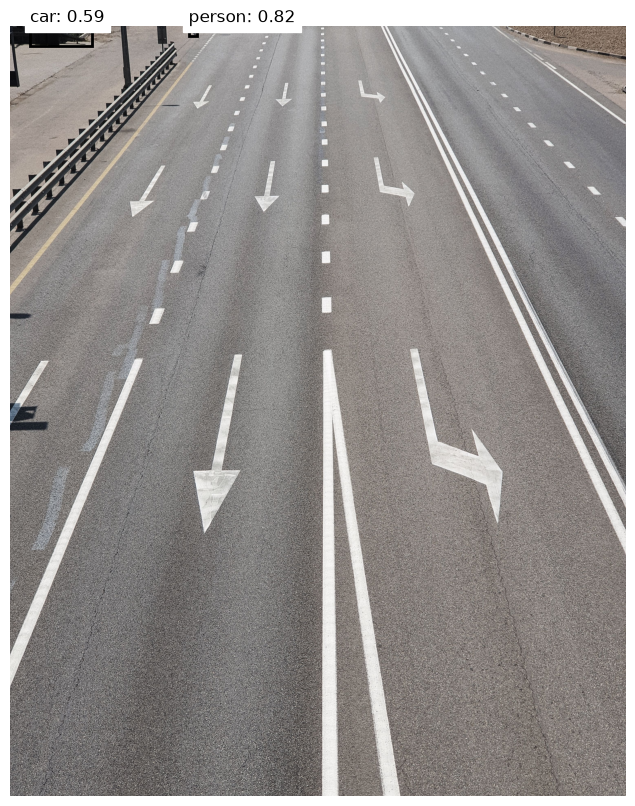

In [20]:
# 18-8D — Visualize Object Detections

fig, ax = plt.subplots(figsize=(8, 10))

ax.imshow(image)

for box, label, score in zip(
    filtered_boxes,
    filtered_labels,
    filtered_scores
):
    x_min, y_min, x_max, y_max = box.cpu().tolist()

    rectangle = Rectangle(
        (x_min, y_min),
        x_max - x_min,
        y_max - y_min,
        fill=False,
        linewidth=2
    )

    ax.add_patch(rectangle)

    class_name = categories[label.item()]

    ax.text(
        x_min,
        y_min - 20,
        f"{class_name}: {score.item():.2f}",
        fontsize=12,
        backgroundcolor="white"
    )

ax.axis("off")
plt.show()

In [21]:
# 19-8D — Inspect Detected Bounding Boxes

for i, (box, label, score) in enumerate(
    zip(filtered_boxes, filtered_labels, filtered_scores)
):
    print(f"Detection {i + 1}")
    print(f"  Class: {categories[label.item()]}")
    print(f"  Confidence: {score.item():.4f}")
    print(f"  Bounding box: {box.cpu().tolist()}")

Detection 1
  Class: person
  Confidence: 0.8179
  Bounding box: [876.1588134765625, 0.4499352276325226, 918.1902465820312, 49.213844299316406]
Detection 2
  Class: car
  Confidence: 0.5856
  Bounding box: [97.70997619628906, 0.0, 402.6199951171875, 96.1975326538086]


In [22]:
# 20-8D — Calculate Bounding Box Dimensions

for i, box in enumerate(filtered_boxes):
    x_min, y_min, x_max, y_max = box.cpu().tolist()

    width = x_max - x_min
    height = y_max - y_min
    area = width * height

    print(f"Detection {i + 1}")
    print(f"  Width: {width:.2f} px")
    print(f"  Height: {height:.2f} px")
    print(f"  Area: {area:.2f} px²")

Detection 1
  Width: 42.03 px
  Height: 48.76 px
  Area: 2049.62 px²
Detection 2
  Width: 304.91 px
  Height: 96.20 px
  Area: 29331.59 px²


In [23]:
# 21-8D — Bounding Box Area Relative to Image

image_area = image_width * image_height

for i, box in enumerate(filtered_boxes):
    x_min, y_min, x_max, y_max = box.cpu().tolist()

    box_area = (x_max - x_min) * (y_max - y_min)
    area_ratio = box_area / image_area

    print(
        f"Detection {i + 1} "
        f"({categories[filtered_labels[i].item()]}): "
        f"{area_ratio:.6%} of image area"
    )

Detection 1 (person): 0.017926% of image area
Detection 2 (car): 0.256535% of image area


In [24]:
# 22-8D — Intersection over Union

def calculate_iou(box_a, box_b):
    x1 = max(box_a[0], box_b[0])
    y1 = max(box_a[1], box_b[1])
    x2 = min(box_a[2], box_b[2])
    y2 = min(box_a[3], box_b[3])

    intersection_width = max(0, x2 - x1)
    intersection_height = max(0, y2 - y1)
    intersection_area = intersection_width * intersection_height

    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])

    union_area = area_a + area_b - intersection_area

    if union_area == 0:
        return 0.0

    return intersection_area / union_area


box_a = [100, 100, 300, 300]
box_b = [150, 150, 350, 350]

iou = calculate_iou(box_a, box_b)

print(f"IoU: {iou:.4f}")

IoU: 0.3913


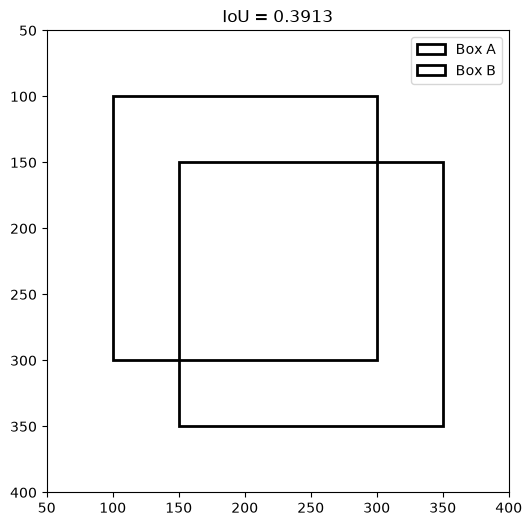

In [25]:
# 23-8D — Visualize Intersection over Union

box_a = [100, 100, 300, 300]
box_b = [150, 150, 350, 350]

fig, ax = plt.subplots(figsize=(6, 6))

rectangle_a = Rectangle(
    (box_a[0], box_a[1]),
    box_a[2] - box_a[0],
    box_a[3] - box_a[1],
    fill=False,
    linewidth=2,
    label="Box A"
)

rectangle_b = Rectangle(
    (box_b[0], box_b[1]),
    box_b[2] - box_b[0],
    box_b[3] - box_b[1],
    fill=False,
    linewidth=2,
    label="Box B"
)

ax.add_patch(rectangle_a)
ax.add_patch(rectangle_b)

ax.set_xlim(50, 400)
ax.set_ylim(400, 50)
ax.set_aspect("equal")
ax.legend()
ax.set_title(f"IoU = {iou:.4f}")

plt.show()

In [26]:
# 24-8D — Non-Maximum Suppression

from torchvision.ops import nms

example_boxes = torch.tensor([
    [100, 100, 300, 300],
    [120, 120, 320, 320],
    [500, 500, 700, 700]
], dtype=torch.float32)

example_scores = torch.tensor([
    0.90,
    0.75,
    0.85
])

iou_threshold = 0.50

keep_indices = nms(
    example_boxes,
    example_scores,
    iou_threshold
)

print("Boxes before NMS:", len(example_boxes))
print("Boxes after NMS:", len(keep_indices))
print("Kept indices:", keep_indices.tolist())

for index in keep_indices:
    print(
        f"Box {index.item()}: "
        f"score = {example_scores[index].item():.2f}"
    )

Boxes before NMS: 3
Boxes after NMS: 2
Kept indices: [0, 2]
Box 0: score = 0.90
Box 2: score = 0.85


In [27]:
# 25-8D — Apply NMS to Model Predictions

iou_threshold = 0.50

keep_indices = nms(
    boxes,
    scores,
    iou_threshold
)

nms_boxes = boxes[keep_indices]
nms_labels = labels[keep_indices]
nms_scores = scores[keep_indices]

print("Detections before NMS:", len(boxes))
print("Detections after NMS:", len(nms_boxes))

for i, (label, score) in enumerate(zip(nms_labels, nms_scores)):
    print(
        f"Detection {i + 1}: "
        f"class = {categories[label.item()]}, "
        f"confidence = {score.item():.4f}"
    )

Detections before NMS: 6
Detections after NMS: 5
Detection 1: class = person, confidence = 0.8179
Detection 2: class = car, confidence = 0.5856
Detection 3: class = car, confidence = 0.1051
Detection 4: class = person, confidence = 0.0798
Detection 5: class = person, confidence = 0.0504


In [28]:
# 26-8D — Confidence Filtering and NMS

confidence_threshold = 0.50
iou_threshold = 0.50

confidence_keep = scores >= confidence_threshold

threshold_boxes = boxes[confidence_keep]
threshold_labels = labels[confidence_keep]
threshold_scores = scores[confidence_keep]

nms_keep = nms(
    threshold_boxes,
    threshold_scores,
    iou_threshold
)

final_boxes = threshold_boxes[nms_keep]
final_labels = threshold_labels[nms_keep]
final_scores = threshold_scores[nms_keep]

print("Initial detections:", len(boxes))
print("After confidence filtering:", len(threshold_boxes))
print("After NMS:", len(final_boxes))

for i, (label, score) in enumerate(
    zip(final_labels, final_scores)
):
    print(
        f"Detection {i + 1}: "
        f"class = {categories[label.item()]}, "
        f"confidence = {score.item():.4f}"
    )

Initial detections: 6
After confidence filtering: 2
After NMS: 2
Detection 1: class = person, confidence = 0.8179
Detection 2: class = car, confidence = 0.5856


## Detection Pipeline

The object-detection process demonstrated in this notebook can be summarized as:

`Image → Preprocessing → Object Detector → Candidate Detections → Confidence Filtering → NMS → Final Detections`

Each stage has a distinct purpose:

- **Preprocessing:** converts the input image into the tensor representation required by the model.
- **Object detector:** predicts bounding boxes, class labels, and confidence scores.
- **Confidence filtering:** removes predictions below a selected confidence threshold.
- **Non-Maximum Suppression (NMS):** removes redundant overlapping predictions.
- **Final detections:** provide the objects that are retained for subsequent perception processing.

For the tested image, Faster R-CNN initially produced six candidate detections. Applying a confidence threshold of 0.50 reduced this to two detections. NMS did not remove any additional detections because the remaining boxes did not overlap sufficiently.

The final predictions were:

| Class | Confidence |
|---|---:|
| person | 0.8179 |
| car | 0.5856 |

This demonstrates the basic inference and post-processing stages of an object-detection pipeline.

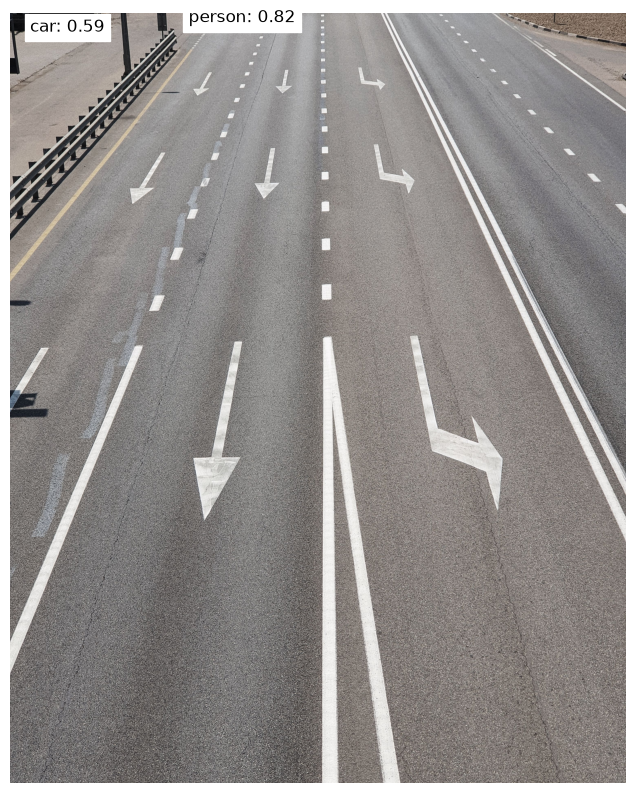

In [29]:
# 27-8D — Visualize Final Detections

fig, ax = plt.subplots(figsize=(8, 10))

ax.imshow(image)

for box, label, score in zip(
    final_boxes,
    final_labels,
    final_scores
):
    x_min, y_min, x_max, y_max = box.cpu().tolist()

    rectangle = Rectangle(
        (x_min, y_min),
        x_max - x_min,
        y_max - y_min,
        fill=False,
        linewidth=2
    )

    ax.add_patch(rectangle)

    class_name = categories[label.item()]

    ax.text(
        x_min,
        y_max - 5,
        f"{class_name}: {score.item():.2f}",
        fontsize=12,
        backgroundcolor="white"
    )

ax.axis("off")
plt.show()

## Model Post-Processing Note

The confidence filtering and NMS operations demonstrated above were
performed explicitly to understand the underlying object-detection
concepts.

Faster R-CNN already performs post-processing as part of its inference
pipeline, including filtering predictions and applying Non-Maximum
Suppression.

Therefore, manually applying the same operations to the final model
output is not generally required for a standard Faster R-CNN inference
workflow.

The explicit filtering and NMS steps in this notebook are used for
educational inspection of the detection pipeline and should be
distinguished from the model's built-in post-processing.

In [30]:
# 28-8D — Test Detection on a Second Image

second_image_path = Path("../../datasets/lane_detection/road_02.jpg")

second_image = Image.open(second_image_path)

second_tensor = transform(second_image).to(device)

with torch.no_grad():
    second_predictions = model([second_tensor])

second_boxes = second_predictions[0]["boxes"]
second_labels = second_predictions[0]["labels"]
second_scores = second_predictions[0]["scores"]

print("Image size:", second_image.size)
print("Number of candidate detections:", len(second_boxes))

Image size: (4140, 2760)
Number of candidate detections: 0


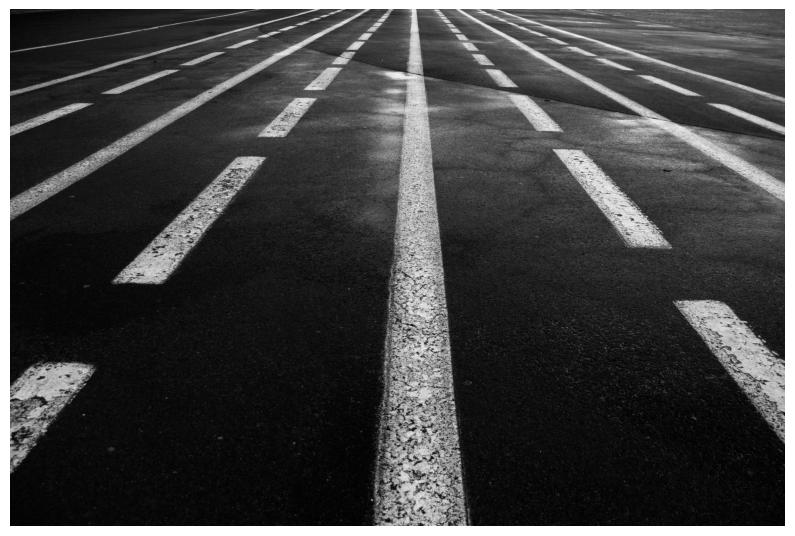

In [31]:
# 29-8D — Display Second Test Image

plt.figure(figsize=(10, 7))
plt.imshow(second_image)
plt.axis("off")
plt.show()

In [32]:
# 30-8D — Test Detection on a Third Image

third_image_path = Path("../../datasets/lane_detection/road_03.jpg")

third_image = Image.open(third_image_path)
third_tensor = transform(third_image).to(device)

with torch.no_grad():
    third_predictions = model([third_tensor])

third_boxes = third_predictions[0]["boxes"]
third_labels = third_predictions[0]["labels"]
third_scores = third_predictions[0]["scores"]

print("Image size:", third_image.size)
print("Number of candidate detections:", len(third_boxes))

Image size: (2592, 3872)
Number of candidate detections: 9


In [33]:
# 31-8D — Inspect Third-Image Predictions

for i, (label, score) in enumerate(
    zip(third_labels, third_scores)
):
    print(
        f"Detection {i + 1}: "
        f"class = {categories[label.item()]}, "
        f"confidence = {score.item():.4f}"
    )

Detection 1: class = baseball bat, confidence = 0.5956
Detection 2: class = baseball bat, confidence = 0.3834
Detection 3: class = baseball bat, confidence = 0.3136
Detection 4: class = airplane, confidence = 0.1426
Detection 5: class = umbrella, confidence = 0.1053
Detection 6: class = airplane, confidence = 0.0684
Detection 7: class = frisbee, confidence = 0.0582
Detection 8: class = umbrella, confidence = 0.0544
Detection 9: class = train, confidence = 0.0520


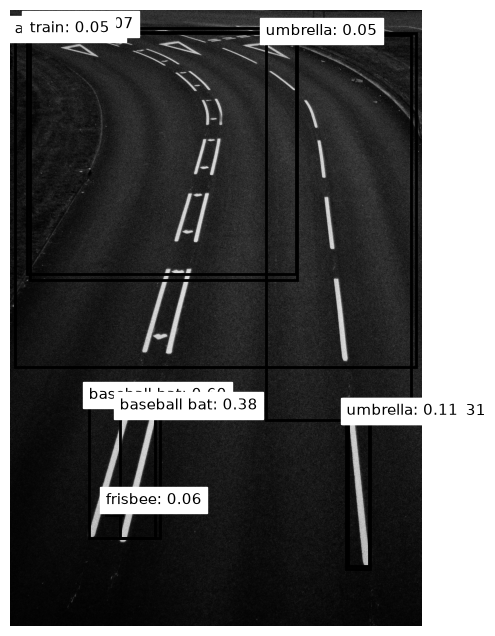

In [34]:
# 32-8D — Visualize Third-Image Detections

fig, ax = plt.subplots(figsize=(10, 8))

ax.imshow(third_image)

for box, label, score in zip(
    third_boxes,
    third_labels,
    third_scores
):
    x_min, y_min, x_max, y_max = box.cpu().tolist()

    rectangle = Rectangle(
        (x_min, y_min),
        x_max - x_min,
        y_max - y_min,
        fill=False,
        linewidth=2
    )

    ax.add_patch(rectangle)

    class_name = categories[label.item()]

    ax.text(
        x_min,
        max(y_min, 20),
        f"{class_name}: {score.item():.2f}",
        fontsize=11,
        backgroundcolor="white"
    )

ax.axis("off")
plt.show()

In [35]:
# 33-8D — Filter Third-Image Predictions

confidence_threshold = 0.50

third_keep = third_scores >= confidence_threshold

third_filtered_boxes = third_boxes[third_keep]
third_filtered_labels = third_labels[third_keep]
third_filtered_scores = third_scores[third_keep]

print("Initial detections:", len(third_boxes))
print("Detections after confidence filtering:", len(third_filtered_boxes))

for i, (label, score) in enumerate(
    zip(third_filtered_labels, third_filtered_scores)
):
    print(
        f"Detection {i + 1}: "
        f"class = {categories[label.item()]}, "
        f"confidence = {score.item():.4f}"
    )

Initial detections: 9
Detections after confidence filtering: 1
Detection 1: class = baseball bat, confidence = 0.5956


## Observation from Multiple Road Images

The pretrained Faster R-CNN model was tested on three road-scene images.

The results demonstrate that a generic object detector does not
necessarily provide reliable detections for every road scene.

For the first image, the model detected a person and a car with
confidence scores above 0.50.

For the second image, no candidate detections were produced.

For the third image, nine candidate detections were produced, but the
predicted classes were inconsistent with the visible road scene. After
applying a confidence threshold of 0.50, only a `baseball bat`
prediction with a confidence of 0.5956 remained.

This demonstrates that confidence thresholding can remove low-confidence
predictions, but it does not guarantee semantic correctness. The
detector's predictions must therefore be interpreted in the context of
the target application and evaluated against appropriate ground-truth
data.

For autonomous-driving applications, a detector trained and evaluated
specifically for relevant road-user classes and operating conditions
would be more appropriate than relying directly on a generic
COCO-pretrained detector.

In [36]:
# 34-8D — Summarize Detection Results

confidence_threshold = 0.50

images = [
    ("road_01.jpg", predictions[0]),
    ("road_02.jpg", second_predictions[0]),
    ("road_03.jpg", third_predictions[0])
]

print(f"{'Image':<15} {'Candidates':<12} {'Above 0.50':<12}")
print("-" * 40)

for image_name, prediction in images:
    candidate_count = len(prediction["boxes"])
    above_threshold = (prediction["scores"] >= confidence_threshold).sum().item()

    print(
        f"{image_name:<15} "
        f"{candidate_count:<12} "
        f"{above_threshold:<12}"
    )

Image           Candidates   Above 0.50  
----------------------------------------
road_01.jpg     6            2           
road_02.jpg     0            0           
road_03.jpg     9            1           


## Multi-Image Detection Results

The pretrained Faster R-CNN model was evaluated on three road-scene
images using the same inference procedure and a confidence threshold
of 0.50.

| Image | Candidate detections | Detections above 0.50 |
|---|---:|---:|
| `road_01.jpg` | 6 | 2 |
| `road_02.jpg` | 0 | 0 |
| `road_03.jpg` | 9 | 1 |

The results show different detector responses across the three images.
The first image produced two detections above the selected confidence
threshold, while the second image produced no candidate detections.
The third image produced one detection above the threshold, but its
predicted class was inconsistent with the visible road scene.

These results are an exploratory demonstration of pretrained object
detection rather than a formal performance evaluation. Since the
images do not have object-detection ground-truth annotations, metrics
such as precision, recall, and mean Average Precision (mAP) cannot be
calculated from this experiment.

The experiment nevertheless demonstrates an important limitation of
using a generic pretrained detector directly for an autonomous-driving
application: model predictions must be evaluated against the specific
objects, operating conditions, and dataset targeted by the perception
system.

## Confidence Threshold Experiment

The pretrained object detector produces candidate detections with different confidence scores. In this experiment, the confidence threshold is varied to examine how the number and type of retained detections change.

In [37]:
# 35-9D — Confidence Threshold Experiment

thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]

print("Confidence Threshold Experiment")
print("--------------------------------")

for threshold in thresholds:
    mask = predictions[0]["scores"] >= threshold
    count = mask.sum().item()
    print(f"Threshold {threshold:.1f}: {count} detections")

Confidence Threshold Experiment
--------------------------------
Threshold 0.1: 4 detections
Threshold 0.3: 2 detections
Threshold 0.5: 2 detections
Threshold 0.7: 1 detections
Threshold 0.9: 0 detections


In [39]:
# 36-9D — Inspect Detections at Different Thresholds

# COCO class names used by the pretrained Faster R-CNN model
coco_classes = weights.meta["categories"]

for threshold in thresholds:
    mask = predictions[0]["scores"] >= threshold
    labels = predictions[0]["labels"][mask]
    scores = predictions[0]["scores"][mask]

    print(f"\nThreshold {threshold:.1f}")

    for label, score in zip(labels, scores):
        class_name = coco_classes[label.item()]
        print(f"  {class_name}: {score.item():.4f}")


Threshold 0.1
  person: 0.8179
  car: 0.5856
  car: 0.1051
  skis: 0.1036

Threshold 0.3
  person: 0.8179
  car: 0.5856

Threshold 0.5
  person: 0.8179
  car: 0.5856

Threshold 0.7
  person: 0.8179

Threshold 0.9


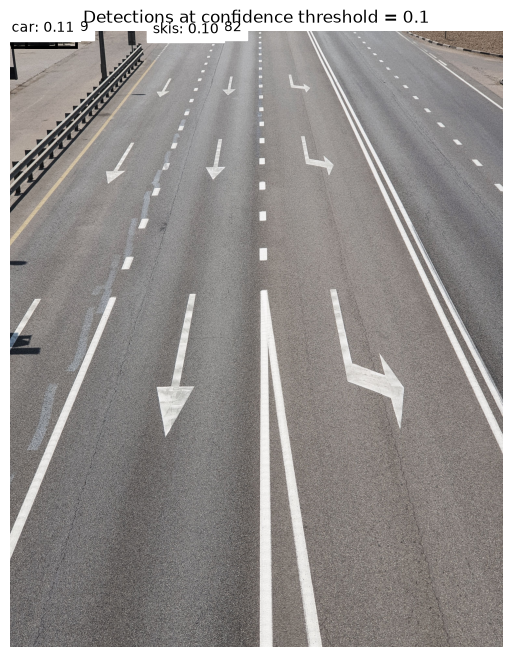

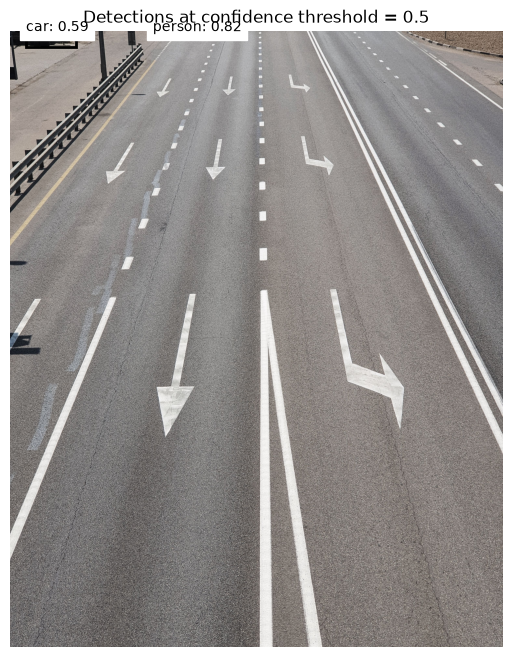

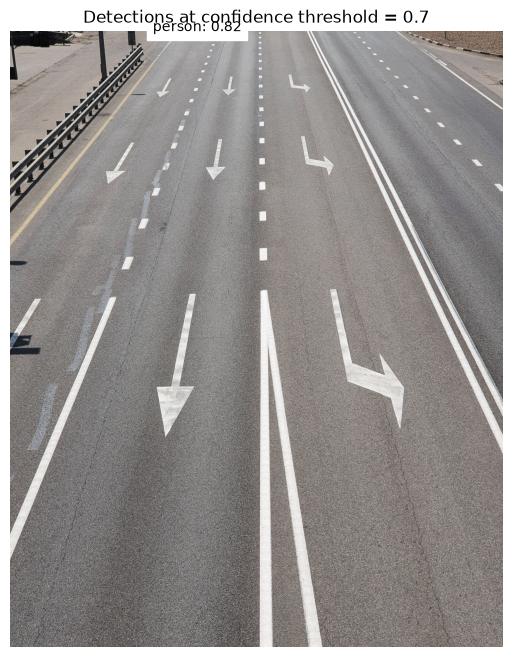

In [40]:
# 37-9D — Visualize Threshold Effect

thresholds_to_visualize = [0.1, 0.5, 0.7]

for threshold in thresholds_to_visualize:
    mask = predictions[0]["scores"] >= threshold

    boxes = predictions[0]["boxes"][mask].cpu()
    labels = predictions[0]["labels"][mask].cpu()
    scores = predictions[0]["scores"][mask].cpu()

    plt.figure(figsize=(10, 8))
    plt.imshow(image)

    ax = plt.gca()

    for box, label, score in zip(boxes, labels, scores):
        x_min, y_min, x_max, y_max = box.tolist()

        rect = plt.Rectangle(
            (x_min, y_min),
            x_max - x_min,
            y_max - y_min,
            fill=False,
            linewidth=2
        )
        ax.add_patch(rect)

        class_name = coco_classes[label.item()]
        ax.text(
            x_min,
            y_min,
            f"{class_name}: {score:.2f}",
            fontsize=10,
            backgroundcolor="white"
        )

    plt.title(f"Detections at confidence threshold = {threshold:.1f}")
    plt.axis("off")
    plt.show()

In [41]:
# 38-9D — Threshold Comparison Across Images

image_predictions = [
    ("road_01.jpg", predictions[0]),
    ("road_02.jpg", second_predictions[0]),
    ("road_03.jpg", third_predictions[0])
]

print("Detection Count by Confidence Threshold")
print("----------------------------------------")

for image_name, prediction in image_predictions:
    print(f"\n{image_name}")

    for threshold in thresholds:
        mask = prediction["scores"] >= threshold
        count = mask.sum().item()

        print(f"  Threshold {threshold:.1f}: {count} detections")

Detection Count by Confidence Threshold
----------------------------------------

road_01.jpg
  Threshold 0.1: 4 detections
  Threshold 0.3: 2 detections
  Threshold 0.5: 2 detections
  Threshold 0.7: 1 detections
  Threshold 0.9: 0 detections

road_02.jpg
  Threshold 0.1: 0 detections
  Threshold 0.3: 0 detections
  Threshold 0.5: 0 detections
  Threshold 0.7: 0 detections
  Threshold 0.9: 0 detections

road_03.jpg
  Threshold 0.1: 5 detections
  Threshold 0.3: 3 detections
  Threshold 0.5: 1 detections
  Threshold 0.7: 0 detections
  Threshold 0.9: 0 detections


In [42]:
# 39-9D — Quantify Threshold Sensitivity

print("Threshold Sensitivity")
print("---------------------")

for image_name, prediction in image_predictions:
    counts = []

    for threshold in thresholds:
        mask = prediction["scores"] >= threshold
        counts.append(mask.sum().item())

    initial_count = counts[0]
    final_count = counts[-1]

    print(f"{image_name}:")
    print(f"  At 0.1: {initial_count} detections")
    print(f"  At 0.9: {final_count} detections")
    print(f"  Detections removed: {initial_count - final_count}")

Threshold Sensitivity
---------------------
road_01.jpg:
  At 0.1: 4 detections
  At 0.9: 0 detections
  Detections removed: 4
road_02.jpg:
  At 0.1: 0 detections
  At 0.9: 0 detections
  Detections removed: 0
road_03.jpg:
  At 0.1: 5 detections
  At 0.9: 0 detections
  Detections removed: 5


## Threshold Sensitivity — Observation

The confidence threshold has a strong effect on the number of retained detections. For `road_01.jpg`, the number of detections decreases from 4 at a threshold of 0.1 to 0 at 0.9. For `road_03.jpg`, the number decreases from 5 to 0 over the same range, while `road_02.jpg` produces no detections at any tested threshold.

This shows that increasing the confidence threshold makes the detector more selective, but it can also remove all available predictions. In addition, thresholding cannot recover objects that the detector fails to propose in the first place. Therefore, confidence threshold selection alone is not sufficient to ensure reliable object detection for road-scene images.

## Qualitative Detection Assessment

At a confidence threshold of 0.5, `road_01.jpg` retains one person and one car detection. These predictions are plausible road-scene objects based on the image content. `road_02.jpg` produces no detections, despite containing a road scene, while `road_03.jpg` retains a baseball bat detection that does not correspond to a meaningful road-scene object.

Because no object-detection ground-truth annotations are available for these images, these observations are qualitative rather than formal false-positive or false-negative measurements. Nevertheless, they demonstrate that a generic COCO-pretrained detector can produce task-irrelevant predictions and can also miss relevant objects in road scenes.

## Object Detection Experiment — Conclusion

The experiment shows that confidence thresholding directly controls the selectivity of the detector. Lower thresholds retain more predictions, including low-confidence and task-irrelevant detections, while higher thresholds remove these predictions but may also eliminate all detections.

Across the three road images, the pretrained detector showed inconsistent behavior: plausible detections were obtained in `road_01.jpg`, no detections were produced for `road_02.jpg`, and task-irrelevant predictions remained in `road_03.jpg`. This indicates that confidence threshold adjustment alone cannot provide reliable road-scene object detection.

The results also reinforce the importance of task-specific training data, appropriate object classes, ground-truth annotations, and quantitative evaluation when developing an object detection system for autonomous driving.